# 03 — Sentiment Modeling

Amazon Fine Food Reviews — binary sentiment classification (positive vs negative).

**Primary model:** TF-IDF + Linear SVM.
**Evaluation rule:** the held-out test set is used only for final evaluation; GridSearchCV runs only on the training set.


In [1]:
import pandas as pd
import sklearn
from pathlib import Path

current_dir = Path.cwd()
candidate_paths = [
    current_dir / "data" / "processed" / "reviews_cleaned.csv",
    current_dir.parent / "data" / "processed" / "reviews_cleaned.csv",
    Path("A:/DS-Review-AI/data/processed/reviews_cleaned.csv"),
]

csv_path = None
for path in candidate_paths:
    if path.exists():
        csv_path = path
        break

if csv_path is None:
    raise FileNotFoundError("Could not locate reviews_cleaned.csv")

df = pd.read_csv(csv_path)
print(f"Loaded {len(df):,} rows from {csv_path}")


Loaded 393,890 rows from a:\DS-Review-AI\data\processed\reviews_cleaned.csv


In [2]:
binary_df = df[df["sentiment_label"] != "neutral"].copy()
print(binary_df["sentiment_label"].value_counts())
print(binary_df["sentiment_label"].value_counts(normalize=True) * 100)


sentiment_label
positive    307019
negative     57103
Name: count, dtype: int64
sentiment_label
positive    84.317619
negative    15.682381
Name: proportion, dtype: float64


In [3]:
# ============================================================
# LEAKAGE-SAFE TRAIN / TEST SPLIT
# ============================================================

from sklearn.model_selection import GroupShuffleSplit

X = binary_df["full_text"].fillna("").astype(str)
y = binary_df["sentiment_label"]

# Keep identical review texts in the same split
groups = X

gss = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    gss.split(X, y, groups=groups)
)

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]
y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

print("Train size:", len(X_train))
print("Test size:", len(X_test))

print("\nTrain class distribution:")
print(y_train.value_counts(normalize=True).round(4))

print("\nTest class distribution:")
print(y_test.value_counts(normalize=True).round(4))

# Verify exact text overlap
overlap = set(X_train).intersection(set(X_test))

print(f"\nExact cross-split text overlap: {len(overlap):,}")

Train size: 291276
Test size: 72846

Train class distribution:
sentiment_label
positive    0.843
negative    0.157
Name: proportion, dtype: float64

Test class distribution:
sentiment_label
positive    0.8439
negative    0.1561
Name: proportion, dtype: float64

Exact cross-split text overlap: 0


In [4]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Fill missing text without fitting anything on the held-out test set.
X_train = X_train.fillna("")
X_test = X_test.fillna("")

tfidf_vec = TfidfVectorizer(max_features=20000, ngram_range=(1, 2), min_df=5)
X_train_tfidf = tfidf_vec.fit_transform(X_train)   # fit ONLY on train
X_test_tfidf = tfidf_vec.transform(X_test)         # transform test using train vocabulary

print("Vocabulary size:", len(tfidf_vec.vocabulary_))
print("Train matrix shape:", X_train_tfidf.shape)


Vocabulary size: 20000
Train matrix shape: (291276, 20000)


In [5]:
print("NaN count in cleaned_text:", binary_df["cleaned_text"].isna().sum())
print("Empty string count in cleaned_text:", (binary_df["cleaned_text"] == "").sum())


NaN count in cleaned_text: 2
Empty string count in cleaned_text: 0


SVM Class-Weight & Regularization Tuning

In [ ]:
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, GridSearchCV
import time

# 1. Verify train/test variables exist
assert 'X_train' in globals() and 'y_train' in globals(), "X_train or y_train not found in namespace."
assert len(X_train) == 291276, f"Expected 291,276 training samples, found {len(X_train)}"

print(f"Starting Class-Weight & C GridSearch on training set ({len(X_train):,} samples)...")
start_time = time.time()

# 2. Pipeline definition (TF-IDF + LinearSVC)
# Strictly uses our validated feature configuration
svm_pipe = Pipeline([
    ('tfidf', TfidfVectorizer(
        max_features=40000,
        ngram_range=(1, 3),
        min_df=5,
        sublinear_tf=True
    )),
    ('clf', LinearSVC(
        max_iter=2000,
        random_state=42
    ))
])

# 3. Parameter Grid: 2 weight options x 4 C values = 8 fits per fold (16 fits total)
param_grid = {
    'clf__class_weight': [None, 'balanced'],
    'clf__C': [0.25, 0.5, 1.0, 2.0]
}

# 4. Stratified 2-Fold CV on training data only
cv = StratifiedKFold(n_splits=4, shuffle=True, random_state=42)

grid_search = GridSearchCV(
    estimator=svm_pipe,
    param_grid=param_grid,
    scoring=['f1_macro', 'accuracy'],
    refit='f1_macro',
    cv=cv,
    n_jobs=4,           # Leverages your i5-12400F cores cleanly
    verbose=2,
    return_train_score=False
)

grid_search.fit(X_train, y_train)

elapsed = (time.time() - start_time) / 60
print(f"\nGridSearch completed in {elapsed:.2f} minutes.")
print(f"Best Configuration: {grid_search.best_params_}")
print(f"Best 2-Fold CV Macro-F1: {grid_search.best_score_:.4f}")

# 5. Tabulate all 8 configurations
results_df = pd.DataFrame(grid_search.cv_results_)[
    ['param_clf__class_weight', 'param_clf__C', 'mean_test_f1_macro', 'std_test_f1_macro', 'mean_test_accuracy']
].sort_values(by='mean_test_f1_macro', ascending=False).reset_index(drop=True)

results_df.columns = ['Class Weight', 'C', 'Mean Macro-F1', 'Std Macro-F1', 'Mean Accuracy']
display(results_df)

Starting Class-Weight & C GridSearch on training set (291,276 samples)...
Fitting 2 folds for each of 8 candidates, totalling 16 fits

GridSearch completed in 7.92 minutes.
Best Configuration: {'clf__C': 0.5, 'clf__class_weight': None}
Best 2-Fold CV Macro-F1: 0.9190


,Class Weight,C,Mean Macro-F1,Std Macro-F1,Mean Accuracy
0,NaN,0.50,0.918980,0.000834,0.958517
1,NaN,0.25,0.917166,0.001478,0.958074
2,NaN,1.00,0.916913,0.001264,0.957144
3,NaN,2.00,0.912336,0.000702,0.954510
4,balanced,0.50,0.911634,0.000020,0.950580
5,balanced,1.00,0.911060,0.000177,0.950882
6,balanced,0.25,0.909995,0.000083,0.949048
7,balanced,2.00,0.908409,0.000333,0.949968


## Baseline model comparison

These models use the same train/test split and the same train-only TF-IDF representation. The test set is not used to select the tuned model.

In [17]:
from sklearn.dummy import DummyClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import classification_report, f1_score, accuracy_score
import pandas as pd

models = {
    "Majority Baseline": DummyClassifier(strategy="most_frequent"),
    "Naive Bayes": MultinomialNB(),
    "Logistic Regression (default)": LogisticRegression(max_iter=1000, random_state=42),
    "Logistic Regression (balanced)": LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42),
    "Linear SVM (default)": LinearSVC(random_state=42),
    "Linear SVM (balanced)": LinearSVC(class_weight="balanced", random_state=42),
}

results = []
for name, model in models.items():
    model.fit(X_train_tfidf, y_train)
    y_pred = model.predict(X_test_tfidf)
    report = classification_report(y_test, y_pred, output_dict=True)
    results.append({
        "Model": name,
        "Accuracy": round(accuracy_score(y_test, y_pred), 4),
        "Macro F1": round(f1_score(y_test, y_pred, average="macro"), 4),
        "Neg Precision": round(report["negative"]["precision"], 4),
        "Neg Recall": round(report["negative"]["recall"], 4),
        "Neg F1": round(report["negative"]["f1-score"], 4),
        "Pos Precision": round(report["positive"]["precision"], 4),
        "Pos Recall": round(report["positive"]["recall"], 4),
        "Pos F1": round(report["positive"]["f1-score"], 4),
    })

comparison_df = pd.DataFrame(results).sort_values("Macro F1", ascending=False)
print(comparison_df.to_string(index=False))
from pathlib import Path

reports_dir = Path("reports")
reports_dir.mkdir(parents=True, exist_ok=True)

comparison_df.to_csv(reports_dir / "model_comparison.csv", index=False)

print("Saved:", reports_dir / "model_comparison.csv")


a:\DS-Review-AI\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
a:\DS-Review-AI\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
a:\DS-Review-AI\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


                         Model  Accuracy  Macro F1  Neg Precision  Neg Recall  Neg F1  Pos Precision  Pos Recall  Pos F1
          Linear SVM (default)    0.9583    0.9192         0.8863      0.8409  0.8630         0.9708      0.9800  0.9754
 Logistic Regression (default)    0.9541    0.9081         0.9052      0.7889  0.8430         0.9618      0.9847  0.9731
         Linear SVM (balanced)    0.9461    0.9046         0.7767      0.9187  0.8418         0.9844      0.9511  0.9675
Logistic Regression (balanced)    0.9435    0.9020         0.7577      0.9380  0.8382         0.9880      0.9445  0.9658
                   Naive Bayes    0.9257    0.8345         0.9031      0.5871  0.7116         0.9283      0.9884  0.9574
             Majority Baseline    0.8439    0.4577         0.0000      0.0000  0.0000         0.8439      1.0000  0.9153
Saved: reports\model_comparison.csv


## Hardware check

In [8]:
import torch
print("CUDA available:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "None detected")
print("PyTorch version:", torch.__version__)


CUDA available: True
GPU: NVIDIA GeForce RTX 3060 Ti
PyTorch version: 2.14.0+cu126


## CV-safe hyperparameter tuning

TF-IDF is inside the pipeline, so it is refit separately inside each CV training fold. The held-out test set is not passed to GridSearchCV.

In [18]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
import time

pipe = Pipeline([
    ("tfidf", TfidfVectorizer(min_df=5)),
    ("clf", LinearSVC(max_iter=2000, random_state=42))
])

param_grid = {
    "tfidf__max_features": [20000, 40000],
    "tfidf__ngram_range": [(1, 2), (1, 3)],
    "clf__C": [0.5, 1.0]
}

cv_strategy = StratifiedKFold(n_splits=2, shuffle=True, random_state=42)
search = GridSearchCV(
    pipe,
    param_grid,
    cv=cv_strategy,
    scoring="f1_macro",
    n_jobs=2,
    verbose=2
)

print("Starting CV-safe GridSearchCV...")
start = time.time()
X_train_filled = X_train.fillna("")
search.fit(X_train_filled, y_train)
elapsed = (time.time() - start) / 60

print(f"\nCompleted in {elapsed:.1f} minutes")
print(f"Best parameters: {search.best_params_}")
print(f"Best CV macro-F1: {search.best_score_:.4f}")


Starting CV-safe GridSearchCV...
Fitting 2 folds for each of 8 candidates, totalling 16 fits

Completed in 9.9 minutes
Best parameters: {'clf__C': 0.5, 'tfidf__max_features': 40000, 'tfidf__ngram_range': (1, 3)}
Best CV macro-F1: 0.9183


In [19]:
from sklearn.metrics import classification_report, f1_score

# The winning model is selected ONLY from training-set cross-validation.
best_model = search.best_estimator_

# Keep the existing downstream variable name used throughout this notebook.
y_pred_best = best_model.predict(X_test.fillna(""))
y_pred_tuned = y_pred_best

tuned_f1 = f1_score(y_test, y_pred_best, average="macro")

print("=== TUNED MODEL — Held-Out Test Set ===")
print(classification_report(
    y_test,
    y_pred_best,
    labels=["negative", "positive"],
    target_names=["Negative", "Positive"],
    digits=4
))
print(f"\nOriginal (untuned) test macro-F1: 0.9109")
print(f"Tuned test macro-F1: {tuned_f1:.4f}")
print(f"Difference: {(tuned_f1 - 0.9109)*100:+.2f} percentage points")


=== TUNED MODEL — Held-Out Test Set ===
              precision    recall  f1-score   support

    Negative     0.9039    0.8441    0.8730     11372
    Positive     0.9715    0.9834    0.9774     61474

    accuracy                         0.9616     72846
   macro avg     0.9377    0.9137    0.9252     72846
weighted avg     0.9609    0.9616    0.9611     72846


Original (untuned) test macro-F1: 0.9109
Tuned test macro-F1: 0.9252
Difference: +1.43 percentage points


In [26]:
best_model = search.best_estimator_

print("Best parameters:", search.best_params_)
print("Best CV Macro-F1:", round(search.best_score_, 4))

Best parameters: {'clf__C': 0.5, 'tfidf__max_features': 40000, 'tfidf__ngram_range': (1, 3)}
Best CV Macro-F1: 0.9183


## Final confusion matrix and error analysis

This section uses the **same tuned model predictions** as the final metrics below. False positives are negative reviews incorrectly classified as positive; false negatives are positive reviews incorrectly classified as negative.

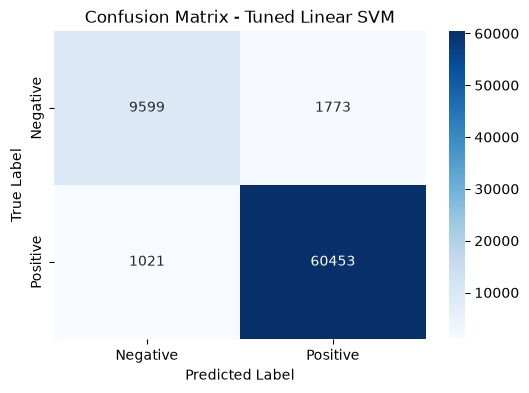

Total Test Samples: 72,846
False Positives: 1,773 (2.43% of test set)
False Negatives: 1,021 (1.40% of test set)

--- SAMPLE FALSE POSITIVES (True: Negative | Pred: Positive) ---
[496 chars | score=0.478] Too expensive This collection<a href="http://www.amazon.com/gp/product/B002TM5458">K-Cup Coffee for Keurig Brewers, Coffee Lover's Collection - 48 Count</a> works out to nearly one...

[342 chars | score=1.524] WHAT CAN I SAY? THE MUSHROOMS ARE HUGE, AND DO COME IN A LARGE JAR, BUT MINE WAS ONLY 2/3 FULL.<br /><br />TO USE, TAKE OUT 1 OR 2 MUSHROOMS, SLICE THEM TO SIZE WANTED (REMEMBERING...

[1515 chars | score=0.346] The placebo effect is powerful I have been a doctor for 50 years. In that time there are now probably 1000 times as many medications and 500 times more medical procedures. Every on...

[530 chars | score=0.134] ancient harvest quinoa rotelle this pasta cooks up and tastes very much like wheat pasta.  the taste is very good.  i only wish i had been able to read, or explo

In [27]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

# 1. Explicitly select the CV-selected tuned model
best_model = search.best_estimator_
y_pred_best = best_model.predict(X_test.fillna(""))
y_pred_tuned = y_pred_best

# SVM decision scores are margins, not probabilities. They are used here only for ROC-AUC/borderline analysis.
y_scores = best_model.decision_function(X_test.fillna(""))

# 2. Confusion Matrix
cm = confusion_matrix(y_test, y_pred_best, labels=["negative", "positive"])
plt.figure(figsize=(6, 4))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"]
)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix - Tuned Linear SVM")
plt.show()

# 3. Construct Error Analysis DataFrame
test_df = pd.DataFrame({
    "text": X_test,
    "true_label": y_test,
    "pred_label": y_pred_best,
    "decision_score": y_scores
})

test_df["correct"] = test_df["true_label"] == test_df["pred_label"]
test_df["length"] = test_df["text"].fillna("").str.len()

fps = test_df[(test_df["true_label"] == "negative") & (test_df["pred_label"] == "positive")]
fns = test_df[(test_df["true_label"] == "positive") & (test_df["pred_label"] == "negative")]

print(f"Total Test Samples: {len(test_df):,}")
print(f"False Positives: {len(fps):,} ({len(fps)/len(test_df)*100:.2f}% of test set)")
print(f"False Negatives: {len(fns):,} ({len(fns)/len(test_df)*100:.2f}% of test set)")

print("\n--- SAMPLE FALSE POSITIVES (True: Negative | Pred: Positive) ---")
for idx, row in fps.sample(min(10, len(fps)), random_state=42).iterrows():
    print(f"[{row['length']} chars | score={row['decision_score']:.3f}] {row['text'][:180]}...\n")

print("--- SAMPLE FALSE NEGATIVES (True: Positive | Pred: Negative) ---")
for idx, row in fns.sample(min(10, len(fns)), random_state=42).iterrows():
    print(f"[{row['length']} chars | score={row['decision_score']:.3f}] {row['text'][:180]}...\n")

print("--- Text Length Summary (Correct vs Misclassified) ---")
print(test_df.groupby("correct")["length"].agg(["count", "mean", "median", "std"]).round(2))

# Borderline-margin diagnostic; SVM decision scores are not probabilities.
borderline_mask = np.abs(y_scores) < 0.5
print(f"\nBorderline |decision score| < 0.5: {borderline_mask.sum():,} ({borderline_mask.mean()*100:.2f}%)")
print(f"Borderline errors: {(~test_df.loc[borderline_mask, 'correct']).sum():,}")


## Complete final metrics

In [28]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
)

y_pred_final = y_pred_best

negative_precision = precision_score(y_test, y_pred_final, pos_label="negative")
negative_recall = recall_score(y_test, y_pred_final, pos_label="negative")
negative_f1 = f1_score(y_test, y_pred_final, pos_label="negative")
positive_precision = precision_score(y_test, y_pred_final, pos_label="positive")
positive_recall = recall_score(y_test, y_pred_final, pos_label="positive")
positive_f1 = f1_score(y_test, y_pred_final, pos_label="positive")

accuracy = accuracy_score(y_test, y_pred_final)
macro_f1 = f1_score(y_test, y_pred_final, average="macro")
roc_auc = roc_auc_score((y_test == "positive").astype(int), y_scores)

final_metrics = pd.DataFrame({
    "Metric": [
        "Accuracy", "Macro F1", "ROC-AUC",
        "Negative Precision", "Negative Recall", "Negative F1", "Negative Support",
        "Positive Precision", "Positive Recall", "Positive F1", "Positive Support"
    ],
    "Value": [
        accuracy, macro_f1, roc_auc,
        negative_precision, negative_recall, negative_f1, (y_test == "negative").sum(),
        positive_precision, positive_recall, positive_f1, (y_test == "positive").sum()
    ]
})

print("=" * 70)
print("FINAL TUNED MODEL — METRICS")
print("=" * 70)
display(final_metrics)

print("\nBest CV parameters:", search.best_params_)
print(f"Held-out test accuracy: {accuracy:.4f}")
print(f"Held-out test macro-F1: {macro_f1:.4f}")
print(f"Held-out test ROC-AUC: {roc_auc:.4f}")


FINAL TUNED MODEL — METRICS


,Metric,Value
0,Accuracy,0.961645
1,Macro F1,0.925183
2,ROC-AUC,0.985537
3,Negative Precision,0.903861
4,Negative Recall,0.844091
5,Negative F1,0.872954
6,Negative Support,11372.000000
7,Positive Precision,0.971507
8,Positive Recall,0.983391
9,Positive F1,0.977413



Best CV parameters: {'clf__C': 0.5, 'tfidf__max_features': 40000, 'tfidf__ngram_range': (1, 3)}
Held-out test accuracy: 0.9616
Held-out test macro-F1: 0.9252
Held-out test ROC-AUC: 0.9855


## DistilBERT zero-shot comparison

This is a comparison against the specific pretrained DistilBERT SST-2 checkpoint below. It is **not** a fine-tuned Amazon-review model.

In [ ]:
import torch
from transformers import pipeline
from sklearn.metrics import classification_report
from tqdm.auto import tqdm

sentiment_pipe = pipeline(
    "sentiment-analysis",
    model="distilbert-base-uncased-finetuned-sst-2-english",
    device=0 if torch.cuda.is_available() else -1,
    batch_size=64,
    truncation=True,
    max_length=512
)

test_texts = X_test.fillna("").tolist()
bert_results = []
for out in tqdm(sentiment_pipe(test_texts), total=len(test_texts), desc="DistilBERT Inference"):
    bert_results.append(out)

bert_preds = ["positive" if r["label"] == "POSITIVE" else "negative" for r in bert_results]

print("\n=== DistilBERT (SST-2 pretrained checkpoint) — Held-Out Test Set ===")
print(classification_report(y_test, bert_preds, labels=["negative", "positive"], digits=4))


In [ ]:
import pandas as pd
from sklearn.metrics import classification_report

svm_rep = classification_report(y_test, y_pred_best, output_dict=True)
bert_rep = classification_report(y_test, bert_preds, output_dict=True)

svm_bert_comparison = pd.DataFrame([
    {
        "Model": "Linear SVM (TF-IDF tuned)",
        "Type": "Supervised (trained on this dataset)",
        "Accuracy": round(svm_rep["accuracy"], 4),
        "Macro F1": round(svm_rep["macro avg"]["f1-score"], 4),
        "Pos F1": round(svm_rep["positive"]["f1-score"], 4),
        "Neg F1": round(svm_rep["negative"]["f1-score"], 4),
        "Inference Speed": "Fast (~seconds)"
    },
    {
        "Model": "DistilBERT (SST-2)",
        "Type": "Pretrained / zero-shot on this task",
        "Accuracy": round(bert_rep["accuracy"], 4),
        "Macro F1": round(bert_rep["macro avg"]["f1-score"], 4),
        "Pos F1": round(bert_rep["positive"]["f1-score"], 4),
        "Neg F1": round(bert_rep["negative"]["f1-score"], 4),
        "Inference Speed": "Moderate (~minutes on GPU)"
    }
])

print("=== TUNED SVM VS SPECIFIC PRETRAINED TRANSFORMER CHECKPOINT ===")
display(svm_bert_comparison)


## Additional pretrained comparisons

In [ ]:
import torch
from transformers import pipeline
from sklearn.metrics import classification_report
from tqdm.auto import tqdm

nlptown_pipe = pipeline(
    "sentiment-analysis",
    model="nlptown/bert-base-multilingual-uncased-sentiment",
    device=0 if torch.cuda.is_available() else -1,
    batch_size=64,
    truncation=True,
    max_length=512
)

nlptown_results = []
for out in tqdm(nlptown_pipe(test_texts), total=len(test_texts), desc="NLP Town BERT Inference"):
    nlptown_results.append(out)

def map_star_to_sentiment(label):
    star_num = int(label.split()[0])
    return "positive" if star_num >= 4 else "negative"

nlptown_preds = [map_star_to_sentiment(r["label"]) for r in nlptown_results]

print("\n=== NLP Town BERT (pretrained product-rating checkpoint) — Held-Out Test Set ===")
print(classification_report(y_test, nlptown_preds, labels=["negative", "positive"], digits=4))


In [ ]:
roberta_pipe = pipeline(
    "sentiment-analysis",
    model="cardiffnlp/twitter-roberta-base-sentiment-latest",
    device=0 if torch.cuda.is_available() else -1,
    batch_size=64,
    truncation=True,
    max_length=512
)

roberta_results = []
for out in tqdm(roberta_pipe(test_texts), total=len(test_texts), desc="RoBERTa Inference"):
    roberta_results.append(out)

# The checkpoint can output positive/negative/neutral. Because the task here is binary,
# neutral is mapped to negative; this mapping is documented rather than hidden.
roberta_preds = [
    r["label"] if r["label"] in ["positive", "negative"] else "negative"
    for r in roberta_results
]

print("\n=== RoBERTa Twitter sentiment checkpoint — Held-Out Test Set ===")
print(classification_report(y_test, roberta_preds, labels=["negative", "positive"], digits=4))


In [ ]:
import nltk
nltk.download("vader_lexicon")
from nltk.sentiment import SentimentIntensityAnalyzer

analyzer = SentimentIntensityAnalyzer()

def vader_predict(text):
    score = analyzer.polarity_scores(str(text))["compound"]
    return "positive" if score >= 0 else "negative"

vader_preds = X_test.fillna("").apply(vader_predict)

print("=== VADER — Held-Out Test Set ===")
print(classification_report(y_test, vader_preds, labels=["negative", "positive"], digits=4))


In [ ]:
import pandas as pd
from sklearn.metrics import classification_report

model_predictions = {
    "Linear SVM (TF-IDF tuned)": y_pred_best,
    "DistilBERT (SST-2, pretrained)": bert_preds,
    "NLP Town BERT (pretrained)": nlptown_preds,
    "RoBERTa (Twitter, pretrained)": roberta_preds,
    "VADER (lexicon)": vader_preds,
}

rows = []
for name, preds in model_predictions.items():
    rep = classification_report(y_test, preds, output_dict=True)
    rows.append({
        "Model": name,
        "Accuracy": round(rep["accuracy"], 4),
        "Macro F1": round(rep["macro avg"]["f1-score"], 4),
        "Negative F1": round(rep["negative"]["f1-score"], 4),
        "Positive F1": round(rep["positive"]["f1-score"], 4),
    })

final_comparison = pd.DataFrame(rows)
print(final_comparison.to_string(index=False))
final_comparison.to_csv("../reports/final_model_comparison.csv", index=False)


## Model interpretation — Linear SVM coefficients

For the final Linear SVM, coefficients indicate which TF-IDF features push the decision function toward the positive or negative class. These are model associations, not causal drivers.

In [29]:
import numpy as np

# The tuned estimator is a Pipeline: TF-IDF -> LinearSVC.
final_tfidf = best_model.named_steps["tfidf"]
final_svm = best_model.named_steps["clf"]
feature_names = final_tfidf.get_feature_names_out()
coefficients = final_svm.coef_[0]

positive_idx = np.argsort(coefficients)[-20:][::-1]
negative_idx = np.argsort(coefficients)[:20]

positive_terms = pd.DataFrame({
    "Term": feature_names[positive_idx],
    "Coefficient": coefficients[positive_idx]
})
negative_terms = pd.DataFrame({
    "Term": feature_names[negative_idx],
    "Coefficient": coefficients[negative_idx]
})

print("=== TOP POSITIVE-ASSOCIATED FEATURES ===")
display(positive_terms)

print("=== TOP NEGATIVE-ASSOCIATED FEATURES ===")
display(negative_terms)


=== TOP POSITIVE-ASSOCIATED FEATURES ===


,Term,Coefficient
0,great,7.869851
1,delicious,6.021932
2,good,5.659868
3,excellent,5.641607
4,best,5.328841
5,not bad,4.605627
6,awesome,4.129517
7,perfect,4.126794
8,wonderful,3.922713
9,yummy,3.904516


=== TOP NEGATIVE-ASSOCIATED FEATURES ===


,Term,Coefficient
0,two stars,-5.288217
1,not,-5.011721
2,disappointing,-4.870174
3,not good,-4.776490
4,disappointed,-4.585573
5,terrible,-4.375396
6,worst,-4.336963
7,disappointment,-4.116300
8,yuck,-4.067015
9,awful,-3.845804


## Reproducibility / final model record

The final model is selected from training-set cross-validation and evaluated once on the held-out test set. Test metrics should not be used to choose another hyperparameter setting.

In [30]:
print("=== FINAL MODEL RECORD ===")
print("Model: TF-IDF + LinearSVC")
print("Selection metric: macro-F1")
print("CV: 2-fold StratifiedKFold, shuffle=True, random_state=42")
print("Best parameters:", search.best_params_)
print("Best CV macro-F1:", round(search.best_score_, 4))
print("Held-out test samples:", len(y_test))
print("Held-out test accuracy:", round(accuracy, 4))
print("Held-out test macro-F1:", round(macro_f1, 4))
print("Held-out test ROC-AUC:", round(roc_auc, 4))
print("Negative false positives:", int(((y_test == "negative") & (y_pred_best == "positive")).sum()))
print("Positive false negatives:", int(((y_test == "positive") & (y_pred_best == "negative")).sum()))


=== FINAL MODEL RECORD ===
Model: TF-IDF + LinearSVC
Selection metric: macro-F1
CV: 2-fold StratifiedKFold, shuffle=True, random_state=42
Best parameters: {'clf__C': 0.5, 'tfidf__max_features': 40000, 'tfidf__ngram_range': (1, 3)}
Best CV macro-F1: 0.9183
Held-out test samples: 72846
Held-out test accuracy: 0.9616
Held-out test macro-F1: 0.9252
Held-out test ROC-AUC: 0.9855
Negative false positives: 1773
Positive false negatives: 1021
